In [149]:
import pandas as pd 
import numpy as np

In [150]:
df = pd.read_csv("Amazon Dataset.csv")

In [151]:
df.head()

,OrderID,OrderDate,CustomerID,CustomerName,ProductID,ProductName,Category,Brand,Quantity,UnitPrice,Discount,Tax,ShippingCost,TotalAmount,PaymentMethod,OrderStatus,City,State,Country,SellerID
0,ORD0000001,2023-01-31,CUST001504,Vihaan Sharma,P00014,Drone Mini,Books,BrightLux,3,106.59,0.00,0.00,0.09,319.86,Debit Card,Delivered,Washington,DC,India,SELL01967
1,ORD0000002,2023-12-30,CUST000178,Pooja Kumar,P00040,Microphone,Home & Kitchen,UrbanStyle,1,251.37,0.05,19.10,1.74,259.64,Amazon Pay,Delivered,Fort Worth,TX,United States,SELL01298
2,ORD0000003,2022-05-10,CUST047516,Sneha Singh,P00044,Power Bank 20000mAh,Clothing,UrbanStyle,3,35.03,0.10,7.57,5.91,108.06,Debit Card,Delivered,Austin,TX,United States,SELL00908
3,ORD0000004,2023-07-18,CUST030059,Vihaan Reddy,P00041,Webcam Full HD,Home & Kitchen,Zenith,5,33.58,0.15,11.42,5.53,159.66,Cash on Delivery,Delivered,Charlotte,NC,India,SELL01164
4,ORD0000005,2023-02-04,CUST048677,Aditya Kapoor,P00029,T-Shirt,Clothing,KiddoFun,2,515.64,0.25,38.67,9.23,821.36,Credit Card,Cancelled,San Antonio,TX,Canada,SELL01411


In [152]:
df.shape

(100000, 20)

In [153]:
df.columns

Index(['OrderID', 'OrderDate', 'CustomerID', 'CustomerName', 'ProductID',
       'ProductName', 'Category', 'Brand', 'Quantity', 'UnitPrice', 'Discount',
       'Tax', 'ShippingCost', 'TotalAmount', 'PaymentMethod', 'OrderStatus',
       'City', 'State', 'Country', 'SellerID'],
      dtype='str')

In [154]:
df.info

<bound method DataFrame.info of           OrderID   OrderDate  CustomerID   CustomerName ProductID  \
0      ORD0000001  2023-01-31  CUST001504  Vihaan Sharma    P00014   
1      ORD0000002  2023-12-30  CUST000178    Pooja Kumar    P00040   
2      ORD0000003  2022-05-10  CUST047516    Sneha Singh    P00044   
3      ORD0000004  2023-07-18  CUST030059   Vihaan Reddy    P00041   
4      ORD0000005  2023-02-04  CUST048677  Aditya Kapoor    P00029   
...           ...         ...         ...            ...       ...   
99995  ORD0099996  2023-03-07  CUST001356    Karan Joshi    P00047   
99996  ORD0099997  2021-11-24  CUST031254  Sunita Kapoor    P00046   
99997  ORD0099998  2023-04-29  CUST012579     Aman Gupta    P00030   
99998  ORD0099999  2021-11-01  CUST026243   Simran Gupta    P00046   
99999  ORD0100000  2021-12-04  CUST029492   Sunita Reddy    P00019   

               ProductName           Category       Brand  Quantity  \
0               Drone Mini              Books   BrightLu

In [155]:
df.describe()

,Quantity,UnitPrice,Discount,Tax,ShippingCost,TotalAmount
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,3.001400,302.905748,0.074226,68.468902,7.406660,918.256479
std,1.413548,171.840797,0.082583,74.131180,4.324057,724.508332
min,1.000000,5.000000,0.000000,0.000000,0.000000,4.270000
25%,2.000000,154.190000,0.000000,15.920000,3.680000,340.890000
50%,3.000000,303.070000,0.050000,45.250000,7.300000,714.315000
75%,4.000000,451.500000,0.100000,96.060000,11.150000,1349.765000
max,5.000000,599.990000,0.300000,538.460000,15.000000,3534.980000


In [156]:
df.isnull().sum()

OrderID          0
OrderDate        0
CustomerID       0
CustomerName     0
ProductID        0
ProductName      0
Category         0
Brand            0
Quantity         0
UnitPrice        0
Discount         0
Tax              0
ShippingCost     0
TotalAmount      0
PaymentMethod    0
OrderStatus      0
City             0
State            0
Country          0
SellerID         0
dtype: int64

In [157]:
df.isnull().sum().sum()

np.int64(0)

In [158]:
df.duplicated().sum()

np.int64(0)

In [159]:
df["OrderID"].duplicated().sum()

np.int64(0)

In [160]:
df.dtypes

OrderID              str
OrderDate            str
CustomerID           str
CustomerName         str
ProductID            str
ProductName          str
Category             str
Brand                str
Quantity           int64
UnitPrice        float64
Discount         float64
Tax              float64
ShippingCost     float64
TotalAmount      float64
PaymentMethod        str
OrderStatus          str
City                 str
State                str
Country              str
SellerID             str
dtype: object

In [161]:
df["OrderDate"] = pd.to_datetime(df["OrderDate"])

In [162]:
df["OrderDate"].dtype

dtype('<M8[us]')

In [163]:
df["Year"] = df["OrderDate"].dt.year

In [164]:
df["Month"] = df["OrderDate"].dt.month

In [165]:
df["DayOfWeek"] = df["OrderDate"].dt.day_name()

In [166]:
df[["OrderDate", "Year", "Month", "DayOfWeek"]].head()

,OrderDate,Year,Month,DayOfWeek
0,2023-01-31,2023,1,Tuesday
1,2023-12-30,2023,12,Saturday
2,2022-05-10,2022,5,Tuesday
3,2023-07-18,2023,7,Tuesday
4,2023-02-04,2023,2,Saturday


In [167]:
df["GrossValue"] = df["Quantity"] * df["UnitPrice"]

In [168]:
df["DiscountAmount"] = df["GrossValue"] * df["Discount"]

In [169]:
df["NetValue"] = df["GrossValue"] - df["DiscountAmount"]

In [170]:
df[["Quantity", "UnitPrice", "Discount",
    "GrossValue", "DiscountAmount", "NetValue"]].head()

,Quantity,UnitPrice,Discount,GrossValue,DiscountAmount,NetValue
0,3,106.59,0.00,319.77,0.0000,319.7700
1,1,251.37,0.05,251.37,12.5685,238.8015
2,3,35.03,0.10,105.09,10.5090,94.5810
3,5,33.58,0.15,167.90,25.1850,142.7150
4,2,515.64,0.25,1031.28,257.8200,773.4600


In [171]:
df["CalculatedTotal"] = (
    df["NetValue"] + df["Tax"] + df["ShippingCost"]
)

In [172]:
df["Difference"] = (
    df["TotalAmount"] - df["CalculatedTotal"]
)

In [173]:
(df["Difference"].abs() > 0.01).sum()

np.int64(0)

In [174]:
df.to_csv("Amazon_Cleaned.csv", index=False)

In [175]:
df.shape

(100000, 28)

In [176]:
df["TotalAmount"].sum()

np.float64(91825647.92)

In [177]:
df["TotalAmount"].mean()

np.float64(918.2564792000001)

In [178]:
df["TotalAmount"].max()

np.float64(3534.98)

In [179]:
df["TotalAmount"].min()

np.float64(4.27)

In [180]:
df["OrderID"].nunique()

100000

In [181]:
df["OrderStatus"].value_counts()

OrderStatus
Delivered    74628
Shipped      15192
Pending       4103
Returned      3049
Cancelled     3028
Name: count, dtype: int64

In [182]:
df.groupby("OrderStatus")["TotalAmount"].sum()

OrderStatus
Cancelled     2851122.39
Delivered    68372677.10
Pending       3737556.98
Returned      2780662.46
Shipped      14083628.99
Name: TotalAmount, dtype: float64

In [183]:
df["OrderStatus"].value_counts(normalize=True) * 100

OrderStatus
Delivered    74.628
Shipped      15.192
Pending       4.103
Returned      3.049
Cancelled     3.028
Name: proportion, dtype: float64

In [184]:
import matplotlib.pyplot as plt

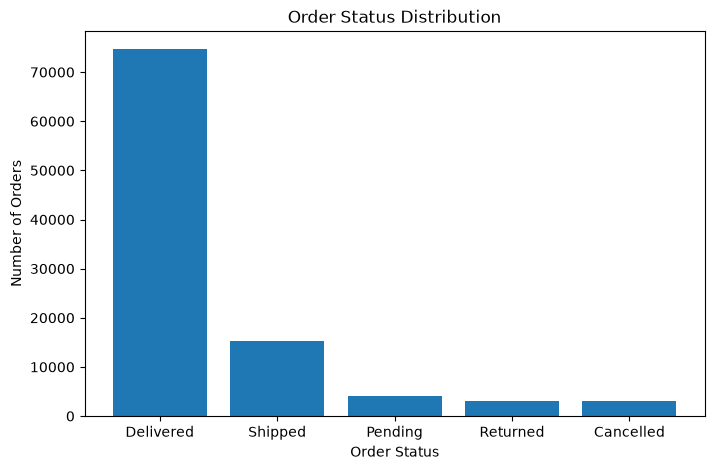

In [185]:
status_counts = df["OrderStatus"].value_counts()

plt.figure(figsize=(8, 5))
plt.bar(status_counts.index, status_counts.values)

plt.title("Order Status Distribution")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")

plt.show()

In [186]:
yearly_sales = df.groupby("Year")["TotalAmount"].sum()

yearly_sales

Year
2020    18529864.02
2021    18248574.81
2022    18367248.41
2023    18513912.19
2024    18166048.49
Name: TotalAmount, dtype: float64

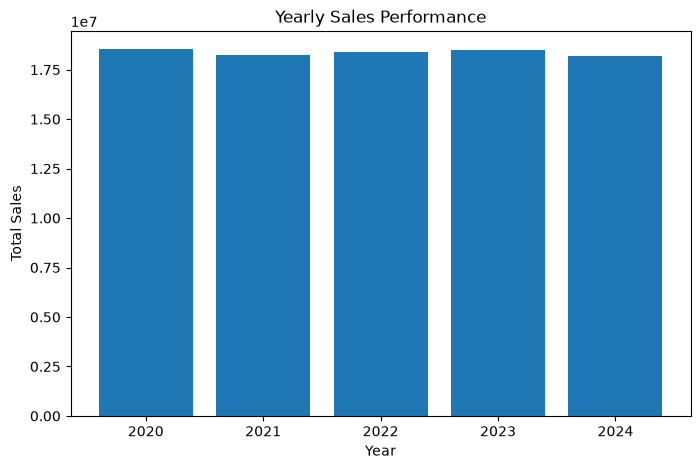

In [187]:
plt.figure(figsize=(8, 5))

plt.bar(yearly_sales.index, yearly_sales.values)

plt.title("Yearly Sales Performance")
plt.xlabel("Year")
plt.ylabel("Total Sales")

plt.show()

In [188]:
yearly_sales.idxmax()

np.int32(2020)

In [189]:
yearly_sales

Year
2020    18529864.02
2021    18248574.81
2022    18367248.41
2023    18513912.19
2024    18166048.49
Name: TotalAmount, dtype: float64

In [190]:
monthly_sales = df.groupby("Month")["TotalAmount"].sum()

monthly_sales

Month
1     7883801.27
2     6931724.49
3     7766527.73
4     7646203.22
5     7864283.27
6     7654636.75
7     7737925.51
8     7890598.37
9     7558970.85
10    7654243.32
11    7495754.13
12    7740979.01
Name: TotalAmount, dtype: float64

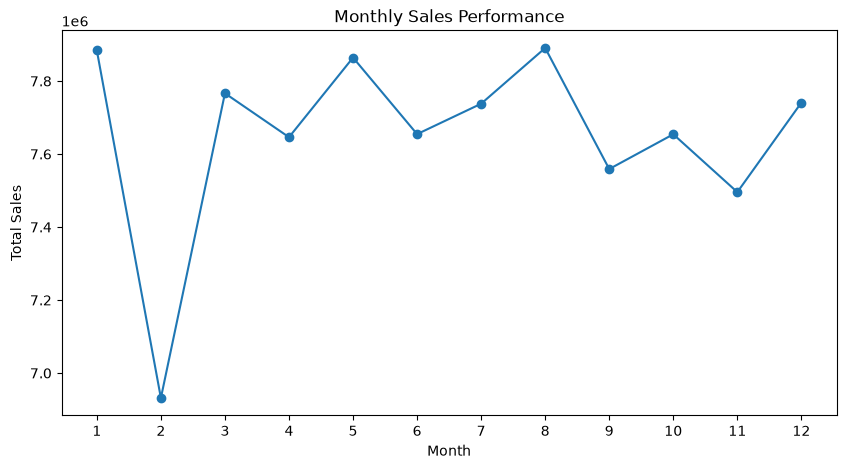

In [191]:
plt.figure(figsize=(10, 5))

plt.plot(monthly_sales.index, monthly_sales.values, marker="o")

plt.title("Monthly Sales Performance")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(range(1, 13))

plt.show()

In [192]:
monthly_sales.idxmax()

np.int32(8)

In [193]:
monthly_sales.idxmin()

np.int32(2)

In [194]:
monthly_sales

Month
1     7883801.27
2     6931724.49
3     7766527.73
4     7646203.22
5     7864283.27
6     7654636.75
7     7737925.51
8     7890598.37
9     7558970.85
10    7654243.32
11    7495754.13
12    7740979.01
Name: TotalAmount, dtype: float64

In [195]:
category_sales = df.groupby("Category")["TotalAmount"].sum()

category_sales

Category
Books                15261837.01
Clothing             15253397.50
Electronics          15584217.18
Home & Kitchen       15163939.36
Sports & Outdoors    15345571.88
Toys & Games         15216684.99
Name: TotalAmount, dtype: float64

In [196]:
category_sales = category_sales.sort_values(ascending=False)

category_sales

Category
Electronics          15584217.18
Sports & Outdoors    15345571.88
Books                15261837.01
Clothing             15253397.50
Toys & Games         15216684.99
Home & Kitchen       15163939.36
Name: TotalAmount, dtype: float64

In [197]:
category_sales.idxmax()

'Electronics'

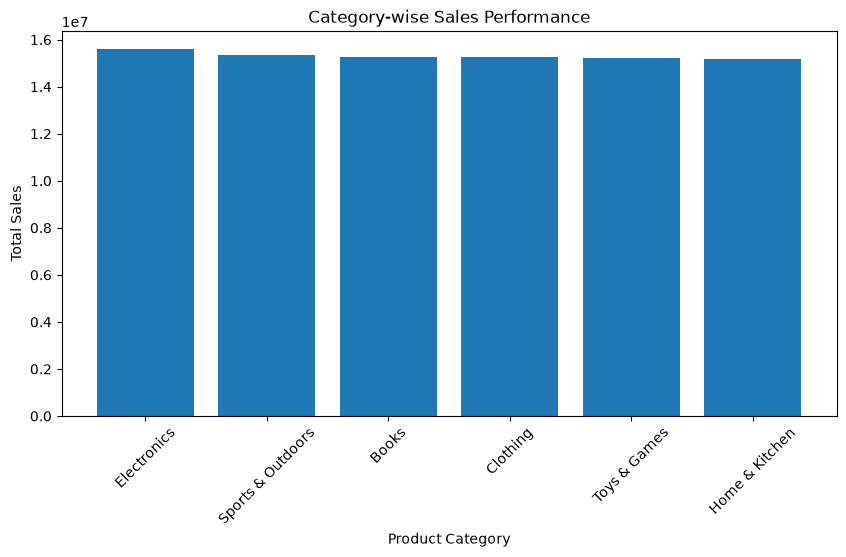

In [198]:
plt.figure(figsize=(10, 5))

plt.bar(category_sales.index, category_sales.values)

plt.title("Category-wise Sales Performance")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)

plt.show()

In [199]:
brand_sales = df.groupby("Brand")["TotalAmount"].sum()

brand_sales

Brand
Apex          9147604.72
BrightLux     9056816.11
CoreTech      9343720.59
FitLife       9061444.68
HomeEase      9045092.83
KiddoFun      9324749.55
NexPro        9078824.97
ReadMore      9278406.63
UrbanStyle    9249027.45
Zenith        9239960.39
Name: TotalAmount, dtype: float64

In [200]:
brand_sales = brand_sales.sort_values(ascending=False)

brand_sales

Brand
CoreTech      9343720.59
KiddoFun      9324749.55
ReadMore      9278406.63
UrbanStyle    9249027.45
Zenith        9239960.39
Apex          9147604.72
NexPro        9078824.97
FitLife       9061444.68
BrightLux     9056816.11
HomeEase      9045092.83
Name: TotalAmount, dtype: float64

In [201]:
brand_sales.idxmax()

'CoreTech'

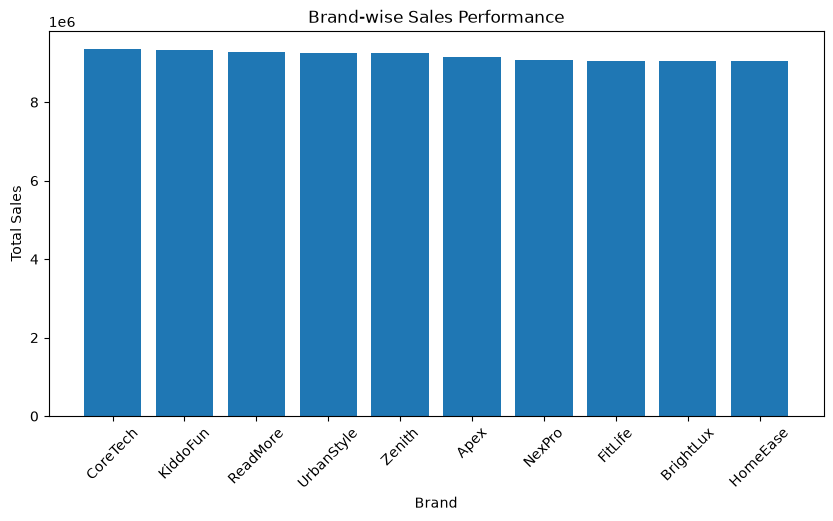

In [202]:
plt.figure(figsize=(10, 5))

plt.bar(brand_sales.index, brand_sales.values)

plt.title("Brand-wise Sales Performance")
plt.xlabel("Brand")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)

plt.show()

In [203]:
df["PaymentMethod"].value_counts()

PaymentMethod
Credit Card         35038
Debit Card          20024
UPI                 15066
Amazon Pay          15017
Net Banking          9927
Cash on Delivery     4928
Name: count, dtype: int64

In [204]:
payment_sales = df.groupby("PaymentMethod")["TotalAmount"].sum()

payment_sales.sort_values(ascending=False)

PaymentMethod
Credit Card         32122158.69
Debit Card          18538678.53
UPI                 13896028.55
Amazon Pay          13697498.42
Net Banking          9055674.57
Cash on Delivery     4515609.16
Name: TotalAmount, dtype: float64

In [205]:
df["PaymentMethod"].value_counts(normalize=True) * 100

PaymentMethod
Credit Card         35.038
Debit Card          20.024
UPI                 15.066
Amazon Pay          15.017
Net Banking          9.927
Cash on Delivery     4.928
Name: proportion, dtype: float64

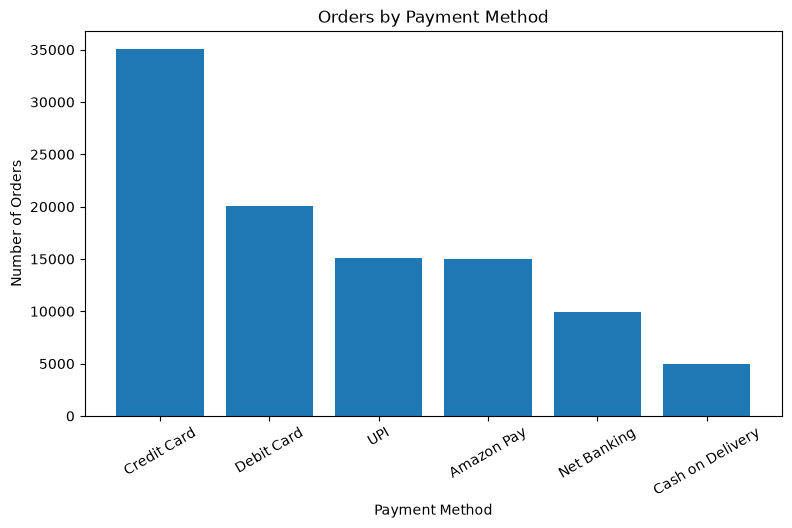

In [206]:
payment_counts = df["PaymentMethod"].value_counts()

plt.figure(figsize=(9, 5))
plt.bar(payment_counts.index, payment_counts.values)

plt.title("Orders by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Orders")
plt.xticks(rotation=30)

plt.show()

In [207]:
country_sales = df.groupby("Country")["TotalAmount"].sum()

country_sales

Country
Australia          3789106.44
Canada             5323757.00
India             13875839.12
United Kingdom     4526896.86
United States     64310048.50
Name: TotalAmount, dtype: float64

In [208]:
country_sales = country_sales.sort_values(ascending=False)

country_sales

Country
United States     64310048.50
India             13875839.12
Canada             5323757.00
United Kingdom     4526896.86
Australia          3789106.44
Name: TotalAmount, dtype: float64

In [209]:
country_sales.idxmax()

'United States'

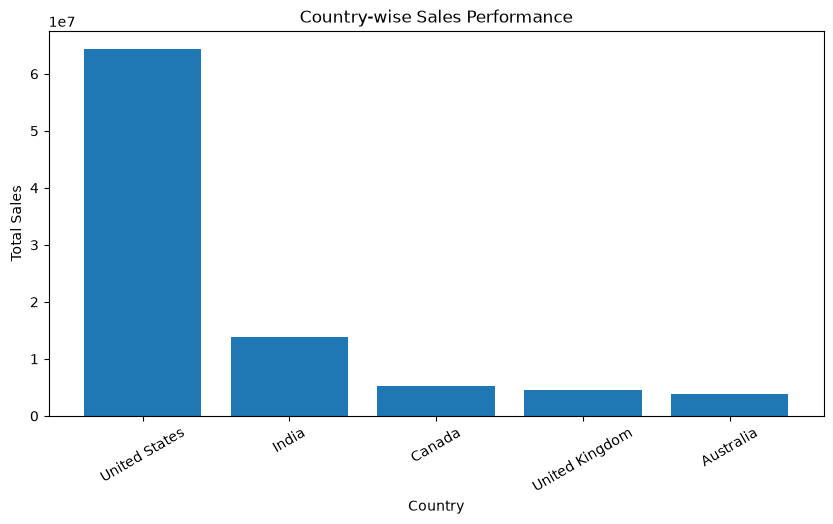

In [210]:
plt.figure(figsize=(10, 5))

plt.bar(country_sales.index, country_sales.values)

plt.title("Country-wise Sales Performance")
plt.xlabel("Country")
plt.ylabel("Total Sales")
plt.xticks(rotation=30)

plt.show()

In [211]:
city_sales = df.groupby("City")["TotalAmount"].sum()

In [212]:
top_cities = city_sales.sort_values(ascending=False).head(10)

top_cities

City
Charlotte       4747701.73
Dallas          4730108.67
San Jose        4669614.33
Seattle         4660962.17
Philadelphia    4650673.88
Denver          4638498.97
Austin          4638403.18
Chicago         4632847.44
Los Angeles     4620629.78
Columbus        4615442.32
Name: TotalAmount, dtype: float64

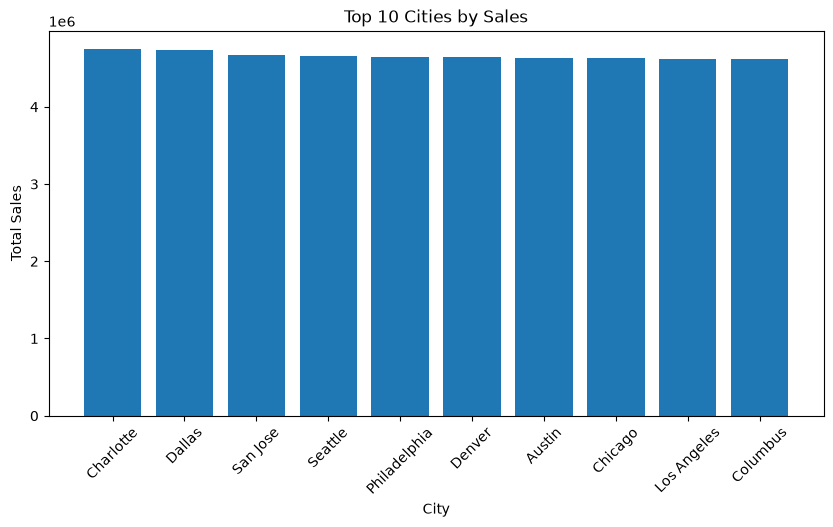

In [213]:
plt.figure(figsize=(10, 5))

plt.bar(top_cities.index, top_cities.values)

plt.title("Top 10 Cities by Sales")
plt.xlabel("City")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)

plt.show()

In [214]:
df["CustomerID"].nunique()

43233

In [215]:
customer_sales = df.groupby("CustomerID")["TotalAmount"].sum()

top_customers = customer_sales.sort_values(ascending=False).head(10)

top_customers

CustomerID
CUST023748    15215.79
CUST009614    12160.96
CUST034178    11418.88
CUST001153    11282.96
CUST004883    11214.44
CUST000787    10962.32
CUST015677    10956.10
CUST042689    10726.80
CUST015231    10638.79
CUST033270    10593.41
Name: TotalAmount, dtype: float64

In [216]:
customer_orders = df.groupby("CustomerID")["OrderID"].count()

customer_orders.describe()

count    43233.000000
mean         2.313048
std          1.257115
min          1.000000
25%          1.000000
50%          2.000000
75%          3.000000
max         10.000000
Name: OrderID, dtype: float64

In [217]:
repeat_customers = (customer_orders > 1).sum()

repeat_customers

np.int64(29701)

In [218]:
repeat_percentage = (repeat_customers / df["CustomerID"].nunique()) * 100

repeat_percentage

np.float64(68.69983577359888)

In [219]:
product_sales = df.groupby("ProductName")["TotalAmount"].sum()

product_sales

ProductName
4K Monitor                     1866774.35
Action Camera                  1829029.24
Air Fryer                      1789927.34
Backpack                       1749971.14
Bluetooth Speaker              1803356.76
Board Game                     1863310.96
Car Charger                    1779795.27
Children's Book                1738112.57
Cookware Set                   1877038.73
Desk Organizer                 1843103.26
Desk Plant                     1759672.62
Dress Shirt                    1896765.36
Drone Mini                     1816203.39
Electric Kettle                1905751.79
External HDD 2TB               1786108.33
Fitness Band                   1784149.50
Gaming Mouse                   1895103.98
Graphic Tablet                 1786772.26
HDMI Cable 2m                  1847856.25
Instant Pot                    1838639.12
Jeans                          1882591.82
Kids Toy Car                   1891082.43
LED Desk Lamp                  1921948.41
Laptop Sleeve         

In [220]:
top_products = product_sales.sort_values(ascending=False).head(10)

top_products

ProductName
Memory Card 128GB      1935138.40
LED Desk Lamp          1921948.41
Mechanical Keyboard    1906963.54
Electric Kettle        1905751.79
Smartwatch             1901275.59
Dress Shirt            1896765.36
Water Bottle           1895467.95
Gaming Mouse           1895103.98
Kids Toy Car           1891082.43
Jeans                  1882591.82
Name: TotalAmount, dtype: float64

In [221]:
product_sales.idxmax()

'Memory Card 128GB'

In [222]:
product_quantity = df.groupby("ProductName")["Quantity"].sum()

top_quantity_products = product_quantity.sort_values(ascending=False).head(10)

top_quantity_products

ProductName
LED Desk Lamp          6344
Water Bottle           6275
Memory Card 128GB      6240
Router                 6202
Board Game             6200
Microphone             6196
Gaming Mouse           6170
Electric Kettle        6165
Mechanical Keyboard    6161
Vacuum Cleaner         6139
Name: Quantity, dtype: int64

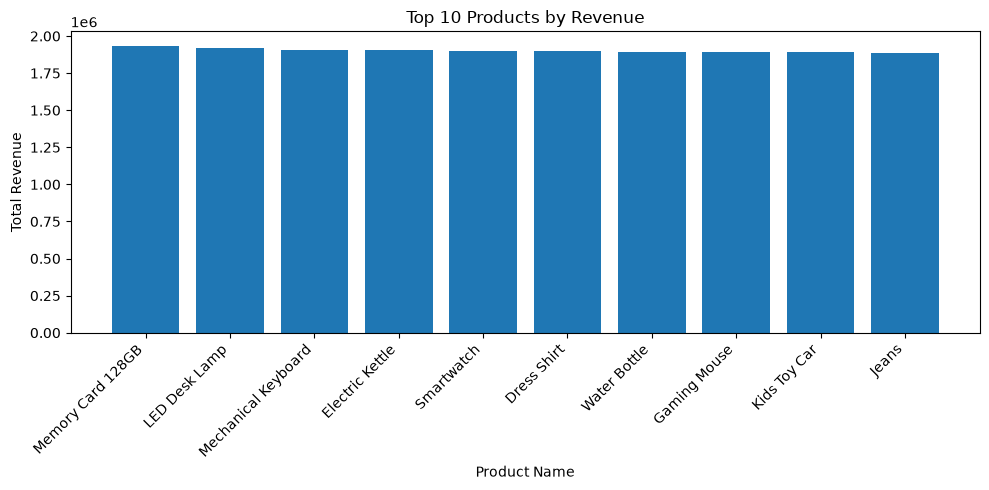

In [223]:
plt.figure(figsize=(10, 5))

plt.bar(top_products.index, top_products.values)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Product Name")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [224]:
open_orders = df[df["OrderStatus"].isin(["Pending", "Shipped"])]

len(open_orders)

19295

In [225]:
open_orders["TotalAmount"].sum()

np.float64(17821185.97)

In [226]:
(len(open_orders) / len(df)) * 100

19.295

In [227]:
from datetime import datetime

old_orders = open_orders[
    open_orders["OrderDate"] < pd.Timestamp("2025-11-26")
]

len(old_orders)

19295

In [228]:
old_orders["TotalAmount"].sum()

np.float64(17821185.97)

In [229]:
resolved_orders = df[
    df["OrderStatus"].isin(["Delivered", "Returned", "Cancelled"])
].copy()

In [230]:
resolved_orders["Failure"] = (
    resolved_orders["OrderStatus"].isin(["Returned", "Cancelled"])
).astype(int)

In [231]:
resolved_orders["Failure"].value_counts()

Failure
0    74628
1     6077
Name: count, dtype: int64

In [232]:
resolved_orders.shape

(80705, 29)

In [233]:
from scipy.stats import chi2_contingency

In [234]:
table = pd.crosstab(
    resolved_orders["PaymentMethod"],
    resolved_orders["Failure"]
)

table

Failure,0,1
PaymentMethod,,
Amazon Pay,11251,933
Cash on Delivery,3633,299
Credit Card,26073,2158
Debit Card,14917,1202
Net Banking,7406,604
UPI,11348,881


In [235]:
chi2, p_value, dof, expected = chi2_contingency(table)

print("Chi-Square Statistic:", chi2)
print("P-value:", p_value)
print("Degrees of Freedom:", dof)

Chi-Square Statistic: 2.832555770793033
P-value: 0.7257817702028766
Degrees of Freedom: 5


In [236]:
from scipy.stats import mannwhitneyu

In [237]:
successful = resolved_orders[
    resolved_orders["Failure"] == 0
]["TotalAmount"]

failed = resolved_orders[
    resolved_orders["Failure"] == 1
]["TotalAmount"]

In [238]:
u_stat, p_value = mannwhitneyu(
    successful,
    failed,
    alternative="two-sided"
)

print("U Statistic:", u_stat)
print("P-value:", p_value)

U Statistic: 224501286.0
P-value: 0.1964623555730809


In [239]:
print("Successful Order Average:", successful.mean())
print("Failed Order Average:", failed.mean())

Successful Order Average: 916.1799472048024
Failed Order Average: 926.7376748395591


In [240]:
customer_order_count = df.groupby("CustomerID")["OrderID"].transform("count")

df["IsRepeatCustomer"] = (customer_order_count > 1).astype(int)

In [241]:
df["IsRepeatCustomer"].value_counts()

IsRepeatCustomer
1    86468
0    13532
Name: count, dtype: int64

In [242]:
df["HasDiscount"] = (df["Discount"] > 0).astype(int)


In [243]:
df["HasDiscount"].value_counts()

HasDiscount
1    59754
0    40246
Name: count, dtype: int64

In [244]:
df["IsWeekend"] = (df["DayOfWeek"].isin(["Saturday", "Sunday"])).astype(int)

In [245]:
df["IsWeekend"].value_counts()

IsWeekend
0    71560
1    28440
Name: count, dtype: int64

In [246]:
df["CustomerOrderCount"] = df.groupby("CustomerID")["OrderID"].transform("count")

In [247]:
df[["CustomerID", "OrderID", "CustomerOrderCount"]].head(10)

,CustomerID,OrderID,CustomerOrderCount
0,CUST001504,ORD0000001,3
1,CUST000178,ORD0000002,2
2,CUST047516,ORD0000003,2
3,CUST030059,ORD0000004,6
4,CUST048677,ORD0000005,1
5,CUST042705,ORD0000006,4
6,CUST037667,ORD0000007,3
7,CUST031165,ORD0000008,3
8,CUST026965,ORD0000009,1
9,CUST029472,ORD0000010,3


In [248]:
df["SellerOrderCount"] = df.groupby("SellerID")["OrderID"].transform("count")

In [249]:
df[["SellerID", "OrderID", "SellerOrderCount"]].head(10)

,SellerID,OrderID,SellerOrderCount
0,SELL01967,ORD0000001,37
1,SELL01298,ORD0000002,54
2,SELL00908,ORD0000003,50
3,SELL01164,ORD0000004,60
4,SELL01411,ORD0000005,53
5,SELL01494,ORD0000006,49
6,SELL01676,ORD0000007,54
7,SELL00510,ORD0000008,55
8,SELL01895,ORD0000009,62
9,SELL01584,ORD0000010,69


In [250]:
df["ProductOrderCount"] = df.groupby("ProductID")["OrderID"].transform("count")

In [251]:
df[["ProductID", "ProductName", "ProductOrderCount"]].head(10)

,ProductID,ProductName,ProductOrderCount
0,P00014,Drone Mini,2026
1,P00040,Microphone,2034
2,P00044,Power Bank 20000mAh,1966
3,P00041,Webcam Full HD,2013
4,P00029,T-Shirt,1978
5,P00023,Cookware Set,2058
6,P00030,Dress Shirt,2007
7,P00028,Jeans,1969
8,P00031,Kids Toy Car,2004
9,P00001,Wireless Earbuds,2008


In [252]:
df["TaxRate"] = df["Tax"] / df["GrossValue"]

In [253]:
df[["GrossValue", "Tax", "TaxRate"]].head(10)

,GrossValue,Tax,TaxRate
0,319.77,0.00,0.000000
1,251.37,19.10,0.075984
2,105.09,7.57,0.072033
3,167.90,11.42,0.068017
4,1031.28,38.67,0.037497
5,1798.92,215.87,0.120000
6,439.62,28.14,0.064010
7,613.02,29.12,0.047503
8,584.36,46.75,0.080002
9,556.42,60.09,0.107994


In [254]:
df["ShippingShare"] = df["ShippingCost"] / df["GrossValue"]

In [255]:
df[["GrossValue", "ShippingCost", "ShippingShare"]].head(10)

,GrossValue,ShippingCost,ShippingShare
0,319.77,0.09,0.000281
1,251.37,1.74,0.006922
2,105.09,5.91,0.056238
3,167.90,5.53,0.032936
4,1031.28,9.23,0.008950
5,1798.92,2.74,0.001523
6,439.62,14.97,0.034052
7,613.02,6.24,0.010179
8,584.36,7.03,0.012030
9,556.42,4.88,0.008770


In [256]:
new_features = [
    "IsRepeatCustomer",
    "HasDiscount",
    "IsWeekend",
    "CustomerOrderCount",
    "SellerOrderCount",
    "ProductOrderCount",
    "TaxRate",
    "ShippingShare"
]

df[new_features].head()

,IsRepeatCustomer,HasDiscount,IsWeekend,CustomerOrderCount,SellerOrderCount,ProductOrderCount,TaxRate,ShippingShare
0,1,0,0,3,37,2026,0.000000,0.000281
1,1,1,1,2,54,2034,0.075984,0.006922
2,1,1,0,2,50,1966,0.072033,0.056238
3,1,1,0,6,60,2013,0.068017,0.032936
4,0,1,1,1,53,1978,0.037497,0.008950


In [257]:
df.shape

(100000, 36)

In [258]:
ml_df = df[
    df["OrderStatus"].isin(["Delivered", "Returned", "Cancelled"])
].copy()

ml_df["Failure"] = (
    ml_df["OrderStatus"].isin(["Returned", "Cancelled"])
).astype(int)

In [259]:
ml_df["Failure"].value_counts()

Failure
0    74628
1     6077
Name: count, dtype: int64

In [260]:
ml_df.shape

(80705, 37)

In [261]:
X = ml_df[
    ["Quantity", "UnitPrice", "Discount", "Tax",
     "ShippingCost", "Year", "Month",
     "IsRepeatCustomer", "HasDiscount", "IsWeekend",
     "CustomerOrderCount", "SellerOrderCount",
     "ProductOrderCount", "TaxRate", "ShippingShare",
     "Category", "Brand", "PaymentMethod", "City", "State", "Country"]
]

y = ml_df["Failure"]

In [262]:
print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (80705, 21)
y Shape: (80705,)


In [263]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [264]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (64564, 21)
Testing data: (16141, 21)


In [265]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "str"]
).columns.tolist()

print("Numerical Features:", numeric_features)
print("Categorical Features:", categorical_features)

Numerical Features: ['Quantity', 'UnitPrice', 'Discount', 'Tax', 'ShippingCost', 'IsRepeatCustomer', 'HasDiscount', 'IsWeekend', 'CustomerOrderCount', 'SellerOrderCount', 'ProductOrderCount', 'TaxRate', 'ShippingShare']
Categorical Features: ['Category', 'Brand', 'PaymentMethod', 'City', 'State', 'Country']


In [266]:
numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Numerical Features:", numeric_features)
print("Categorical Features:", categorical_features)

Numerical Features: ['Quantity', 'UnitPrice', 'Discount', 'Tax', 'ShippingCost', 'Year', 'Month', 'IsRepeatCustomer', 'HasDiscount', 'IsWeekend', 'CustomerOrderCount', 'SellerOrderCount', 'ProductOrderCount', 'TaxRate', 'ShippingShare']
Categorical Features: ['Category', 'Brand', 'PaymentMethod', 'City', 'State', 'Country']


In [267]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

In [268]:
print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [269]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

In [270]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](21,)","['Quantity','UnitPrice','Discount',...,'City','State','Country']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,21
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all re

In [271]:
y_pred = model.predict(X_test)

In [272]:
print(y_pred[:10])

[0 0 1 1 0 1 1 0 0 1]


In [273]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100)

Model Accuracy: 0.49755281581066846
Accuracy Percentage: 49.755281581066846


In [274]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[7434 7492]
 [ 618  597]]


In [275]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.92      0.50      0.65     14926
           1       0.07      0.49      0.13      1215

    accuracy                           0.50     16141
   macro avg       0.50      0.49      0.39     16141
weighted avg       0.86      0.50      0.61     16141



In [276]:
from sklearn.metrics import roc_auc_score

y_probability = model.predict_proba(X_test)[:, 1]

roc_auc = roc_auc_score(y_test, y_probability)

print("ROC-AUC Score:", roc_auc)

ROC-AUC Score: 0.4919826149194738


In [277]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

In [278]:
dt_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=10,
        class_weight="balanced",
        random_state=42
    ))
])

In [279]:
dt_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](21,)","['Quantity','UnitPrice','Discount',...,'City','State','Country']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,21
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all re

In [280]:
dt_pred = dt_model.predict(X_test)

In [281]:
from sklearn.metrics import accuracy_score

dt_accuracy = accuracy_score(y_test, dt_pred)

print("Decision Tree Accuracy:", dt_accuracy)
print("Accuracy Percentage:", dt_accuracy * 100)

Decision Tree Accuracy: 0.4292794746298247
Accuracy Percentage: 42.927947462982466


In [282]:
from sklearn.metrics import roc_auc_score

dt_probability = dt_model.predict_proba(X_test)[:, 1]

dt_roc_auc = roc_auc_score(y_test, dt_probability)

print("Decision Tree ROC-AUC:", dt_roc_auc)

Decision Tree ROC-AUC: 0.4993185310908301


In [283]:
dt_pred = dt_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, dt_pred))
print("ROC-AUC:", roc_auc_score(
    y_test, dt_model.predict_proba(X_test)[:, 1]
))

Accuracy: 0.4292794746298247
ROC-AUC: 0.4993185310908301


In [284]:
from sklearn.ensemble import RandomForestClassifier

In [285]:
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

In [286]:
rf_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](21,)","['Quantity','UnitPrice','Discount',...,'City','State','Country']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,21
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all re

In [287]:
rf_pred = rf_model.predict(X_test)

In [288]:
rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:", rf_accuracy)
print("Accuracy Percentage:", rf_accuracy * 100)

Random Forest Accuracy: 0.7378105445759247
Accuracy Percentage: 73.78105445759246


In [289]:
rf_probability = rf_model.predict_proba(X_test)[:, 1]

rf_roc_auc = roc_auc_score(y_test, rf_probability)

print("Random Forest ROC-AUC:", rf_roc_auc)

Random Forest ROC-AUC: 0.49752099383019327


In [290]:
print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           0       0.92      0.78      0.85     14926
           1       0.07      0.21      0.11      1215

    accuracy                           0.74     16141
   macro avg       0.50      0.50      0.48     16141
weighted avg       0.86      0.74      0.79     16141



In [291]:
rf_probability = rf_model.predict_proba(X_test)[:, 1]

rf_roc_auc = roc_auc_score(y_test, rf_probability)

print("Random Forest ROC-AUC:", rf_roc_auc)

Random Forest ROC-AUC: 0.49752099383019327


In [292]:
from sklearn.ensemble import GradientBoostingClassifier

In [293]:
gb_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

In [294]:
gb_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](21,)","['Quantity','UnitPrice','Discount',...,'City','State','Country']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,21
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all re

In [295]:
gb_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](21,)","['Quantity','UnitPrice','Discount',...,'City','State','Country']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,21
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all re

In [296]:
gb_accuracy = accuracy_score(y_test, gb_pred)

print("Gradient Boosting Accuracy:", gb_accuracy)
print("Accuracy Percentage:", gb_accuracy * 100)

NameError: name 'gb_pred' is not defined

In [298]:
gb_probability = gb_model.predict_proba(X_test)[:, 1]

gb_roc_auc = roc_auc_score(y_test, gb_probability)

print("Gradient Boosting ROC-AUC:", gb_roc_auc)

Gradient Boosting ROC-AUC: 0.5030276938245137


In [299]:
gb_pred = gb_model.predict(X_test)

In [300]:
gb_accuracy = accuracy_score(y_test, gb_pred)

print("Gradient Boosting Accuracy:", gb_accuracy)
print("Accuracy Percentage:", gb_accuracy * 100)

Gradient Boosting Accuracy: 0.9247258534167647
Accuracy Percentage: 92.47258534167648


In [301]:
gb_probability = gb_model.predict_proba(X_test)[:, 1]

gb_roc_auc = roc_auc_score(y_test, gb_probability)

print("Gradient Boosting ROC-AUC:", gb_roc_auc)

Gradient Boosting ROC-AUC: 0.5030276938245137


In [302]:
print(classification_report(y_test, gb_pred))

              precision    recall  f1-score   support

           0       0.92      1.00      0.96     14926
           1       0.00      0.00      0.00      1215

    accuracy                           0.92     16141
   macro avg       0.46      0.50      0.48     16141
weighted avg       0.86      0.92      0.89     16141



C:\Users\BSES\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\BSES\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\BSES\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [303]:
print("Gradient Boosting Predictions:")
print(pd.Series(gb_pred).value_counts())

Gradient Boosting Predictions:
0    16141
Name: count, dtype: int64


In [304]:
print("Accuracy:", accuracy_score(y_test, gb_pred))

gb_probability = gb_model.predict_proba(X_test)[:, 1]

print("ROC-AUC:", roc_auc_score(y_test, gb_probability))

Accuracy: 0.9247258534167647
ROC-AUC: 0.5030276938245137


In [305]:
print(classification_report(y_test, gb_pred, zero_division=0))

              precision    recall  f1-score   support

           0       0.92      1.00      0.96     14926
           1       0.00      0.00      0.00      1215

    accuracy                           0.92     16141
   macro avg       0.46      0.50      0.48     16141
weighted avg       0.86      0.92      0.89     16141



In [306]:
from sklearn.utils.class_weight import compute_sample_weight

sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

gb_model.fit(
    X_train,
    y_train,
    classifier__sample_weight=sample_weights
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](21,)","['Quantity','UnitPrice','Discount',...,'City','State','Country']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,21
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all re

In [307]:
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score

gb_pred = gb_model.predict(X_test)

gb_probability = gb_model.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, gb_pred))

print("ROC-AUC:", roc_auc_score(y_test, gb_probability))

print("\nClassification Report:")
print(classification_report(y_test, gb_pred, zero_division=0))

Accuracy: 0.5491605228920141
ROC-AUC: 0.5001587805740143

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.56      0.70     14926
           1       0.08      0.46      0.13      1215

    accuracy                           0.55     16141
   macro avg       0.50      0.51      0.41     16141
weighted avg       0.86      0.55      0.65     16141



In [308]:
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline

svm_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LinearSVC(
        class_weight="balanced",
        random_state=42,
        max_iter=2000
    ))
])

svm_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](21,)","['Quantity','UnitPrice','Discount',...,'City','State','Country']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,21
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all re

In [309]:
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score

svm_pred = svm_model.predict(X_test)

svm_accuracy = accuracy_score(y_test, svm_pred)

svm_scores = svm_model.decision_function(X_test)

svm_roc_auc = roc_auc_score(y_test, svm_scores)

print("SVM Accuracy:", svm_accuracy)
print("SVM ROC-AUC:", svm_roc_auc)

print("\nClassification Report:")
print(classification_report(y_test, svm_pred, zero_division=0))

SVM Accuracy: 0.49829626417198436
SVM ROC-AUC: 0.49207497729539806

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.50      0.65     14926
           1       0.07      0.49      0.13      1215

    accuracy                           0.50     16141
   macro avg       0.50      0.49      0.39     16141
weighted avg       0.86      0.50      0.61     16141



In [310]:
import xgboost

print(xgboost.__version__)

3.4.1


In [311]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [312]:
import xgboost

print(xgboost.__version__)

3.4.1


In [313]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

xgb_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=100,
        max_depth=5,
        learning_rate=0.1,
        scale_pos_weight=(
            (y_train == 0).sum() / (y_train == 1).sum()
        ),
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

xgb_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](21,)","['Quantity','UnitPrice','Discount',...,'City','State','Country']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,21
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all re

In [314]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()

categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

In [315]:
ml_df = df[
    df["OrderStatus"].isin(["Delivered", "Returned", "Cancelled"])
].copy()

ml_df["Failure"] = (
    ml_df["OrderStatus"].isin(["Returned", "Cancelled"])
).astype(int)

In [316]:
import os

print(os.listdir())

['.anaconda', '.conda', '.continuum', '.gitconfig', '.ipynb_checkpoints', '.ipython', '.jupyter', '.virtual_documents', 'Amazon Dataset.csv', 'Amazon_Cleaned.csv', 'anaconda3', 'anaconda_projects', 'AppData', 'Application Data', 'Contacts', 'Cookies', 'Documents', 'Downloads', 'Favorites', 'Links', 'Local Settings', 'Music', 'My Documents', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{6724674c-05f6-11f1-af30-e28265942663}.TM.blf', 'NTUSER.DAT{6724674c-05f6-11f1-af30-e28265942663}.TMContainer00000000000000000001.regtrans-ms', 'NTUSER.DAT{6724674c-05f6-11f1-af30-e28265942663}.TMContainer00000000000000000002.regtrans-ms', 'ntuser.ini', 'OneDrive', 'PrintHood', 'python', 'Recent', 'Saved Games', 'Searches', 'SendTo', 'Start Menu', 'Templates', 'Untitled.ipynb', 'Untitled1.ipynb', 'Untitled2.ipynb', 'Videos', 'warehouse_location.ipynb']


In [317]:
import pandas as pd

df = pd.read_csv("Amazon_Cleaned.csv")

df["OrderDate"] = pd.to_datetime(df["OrderDate"])

print(df.shape)

(100000, 28)


In [318]:
ml_df = df[
    df["OrderStatus"].isin(["Delivered", "Returned", "Cancelled"])
].copy()

ml_df["Failure"] = (
    ml_df["OrderStatus"].isin(["Returned", "Cancelled"])
).astype(int)

In [319]:
X = ml_df[
    ["Quantity", "UnitPrice", "Discount", "Tax",
     "ShippingCost", "Year", "Month",
     "IsRepeatCustomer", "HasDiscount", "IsWeekend",
     "CustomerOrderCount", "SellerOrderCount",
     "ProductOrderCount", "TaxRate", "ShippingShare",
     "Category", "Brand", "PaymentMethod", "City",
     "State", "Country"]
]

y = ml_df["Failure"]

print(X.shape, y.shape)

KeyError: "['IsRepeatCustomer', 'HasDiscount', 'IsWeekend', 'CustomerOrderCount', 'SellerOrderCount', 'ProductOrderCount', 'TaxRate', 'ShippingShare'] not in index"

In [ ]:
# Customer repeat information
customer_order_count = df.groupby("CustomerID")["OrderID"].transform("count")

df["IsRepeatCustomer"] = (customer_order_count > 1).astype(int)

# Discount information
df["HasDiscount"] = (df["Discount"] > 0).astype(int)

# Weekend information
df["IsWeekend"] = (
    df["DayOfWeek"].isin(["Saturday", "Sunday"])
).astype(int)

# Order counts
df["CustomerOrderCount"] = customer_order_count

df["SellerOrderCount"] = df.groupby("SellerID")["OrderID"].transform("count")

df["ProductOrderCount"] = df.groupby("ProductID")["OrderID"].transform("count")

# Financial ratios
df["TaxRate"] = df["Tax"] / df["GrossValue"]

df["ShippingShare"] = df["ShippingCost"] / df["GrossValue"]

In [ ]:
ml_df = df[
    df["OrderStatus"].isin(["Delivered", "Returned", "Cancelled"])
].copy()

ml_df["Failure"] = (
    ml_df["OrderStatus"].isin(["Returned", "Cancelled"])
).astype(int)

X = ml_df[
    ["Quantity", "UnitPrice", "Discount", "Tax",
     "ShippingCost", "Year", "Month",
     "IsRepeatCustomer", "HasDiscount", "IsWeekend",
     "CustomerOrderCount", "SellerOrderCount",
     "ProductOrderCount", "TaxRate", "ShippingShare",
     "Category", "Brand", "PaymentMethod", "City",
     "State", "Country"]
]

y = ml_df["Failure"]

print("X shape:", X.shape)
print("y shape:", y.shape)

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()

categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

In [ ]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

xgb_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=100,
        max_depth=5,
        learning_rate=0.1,
        scale_pos_weight=(
            (y_train == 0).sum() / (y_train == 1).sum()
        ),
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

xgb_model.fit(X_train, y_train)

In [ ]:
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score

xgb_pred = xgb_model.predict(X_test)

xgb_probability = xgb_model.predict_proba(X_test)[:, 1]

xgb_accuracy = accuracy_score(y_test, xgb_pred)

xgb_roc_auc = roc_auc_score(y_test, xgb_probability)

print("XGBoost Accuracy:", xgb_accuracy)
print("XGBoost ROC-AUC:", xgb_roc_auc)

print("\nClassification Report:")
print(classification_report(y_test, xgb_pred, zero_division=0))

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Gradient Boosting",
        "SVM",
        "XGBoost"
    ],
    "ROC_AUC": [
        0.49198,
        0.49752,
        0.50016,
        0.49207,
        0.47969
    ]
})

plt.figure(figsize=(9, 5))
plt.bar(results["Model"], results["ROC_AUC"])

plt.axhline(y=0.5, linestyle="--", label="Random baseline")

plt.title("ROC-AUC Comparison of Classification Models")
plt.xlabel("Models")
plt.ylabel("ROC-AUC")
plt.xticks(rotation=25)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
reg_df = df.copy()

X_reg = reg_df[
    ["Quantity", "UnitPrice", "Discount", "Tax",
     "ShippingCost", "Year", "Month",
     "IsRepeatCustomer", "HasDiscount", "IsWeekend",
     "CustomerOrderCount", "SellerOrderCount",
     "ProductOrderCount", "TaxRate", "ShippingShare",
     "Category", "Brand", "PaymentMethod", "City",
     "State", "Country"]
]

y_reg = reg_df["TotalAmount"]

print("X shape:", X_reg.shape)
print("y shape:", y_reg.shape)

In [ ]:
from sklearn.model_selection import train_test_split

X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg,
    y_reg,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_reg_train.shape)
print("Testing data:", X_reg_test.shape)

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_features_reg = X_reg.select_dtypes(include=["number"]).columns.tolist()

cat_features_reg = X_reg.select_dtypes(exclude=["number"]).columns.tolist()

preprocessor_reg = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_features_reg),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features_reg)
    ]
)

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

lr_model = Pipeline(steps=[
    ("preprocessor", preprocessor_reg),
    ("regressor", LinearRegression())
])

lr_model.fit(X_reg_train, y_reg_train)

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

lr_pred = lr_model.predict(X_reg_test)

mae = mean_absolute_error(y_reg_test, lr_pred)

rmse = np.sqrt(mean_squared_error(y_reg_test, lr_pred))

r2 = r2_score(y_reg_test, lr_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

In [ ]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline

dt_reg_model = Pipeline(steps=[
    ("preprocessor", preprocessor_reg),
    ("regressor", DecisionTreeRegressor(
        max_depth=10,
        random_state=42
    ))
])

dt_reg_model.fit(X_reg_train, y_reg_train)

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

dt_reg_pred = dt_reg_model.predict(X_reg_test)

dt_mae = mean_absolute_error(y_reg_test, dt_reg_pred)

dt_rmse = np.sqrt(mean_squared_error(y_reg_test, dt_reg_pred))

dt_r2 = r2_score(y_reg_test, dt_reg_pred)

print("Decision Tree MAE:", dt_mae)
print("Decision Tree RMSE:", dt_rmse)
print("Decision Tree R2:", dt_r2)

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

rf_reg_model = Pipeline(steps=[
    ("preprocessor", preprocessor_reg),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    ))
])

rf_reg_model.fit(X_reg_train, y_reg_train)

In [ ]:
rf_reg_pred = rf_reg_model.predict(X_reg_test)

rf_mae = mean_absolute_error(y_reg_test, rf_reg_pred)

rf_rmse = np.sqrt(mean_squared_error(y_reg_test, rf_reg_pred))

rf_r2 = r2_score(y_reg_test, rf_reg_pred)

print("Random Forest MAE:", rf_mae)
print("Random Forest RMSE:", rf_rmse)
print("Random Forest R2:", rf_r2)

In [ ]:
rf_reg_pred = rf_reg_model.predict(X_reg_test)

rf_mae = mean_absolute_error(y_reg_test, rf_reg_pred)
rf_rmse = np.sqrt(mean_squared_error(y_reg_test, rf_reg_pred))
rf_r2 = r2_score(y_reg_test, y_reg_pred)

print("Random Forest MAE:", rf_mae)
print("Random Forest RMSE:", rf_rmse)
print("Random Forest R2:", rf_r2)

In [ ]:
print("df:", "df" in globals())
print("X_reg:", "X_reg" in globals())
print("X_reg_train:", "X_reg_train" in globals())
print("preprocessor_reg:", "preprocessor_reg" in globals())

In [ ]:
X_reg = df[
    ["Quantity", "UnitPrice", "Discount", "Tax",
     "ShippingCost", "Year", "Month",
     "IsRepeatCustomer", "HasDiscount", "IsWeekend",
     "CustomerOrderCount", "SellerOrderCount",
     "ProductOrderCount", "TaxRate", "ShippingShare",
     "Category", "Brand", "PaymentMethod", "City",
     "State", "Country"]
]

y_reg = df["TotalAmount"]

print(X_reg.shape, y_reg.shape)

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

rf_reg_model = Pipeline(steps=[
    ("preprocessor", preprocessor_reg),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    ))
])

rf_reg_model.fit(X_reg_train, y_reg_train)

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_features_reg = X_reg.select_dtypes(include=["number"]).columns.tolist()

cat_features_reg = X_reg.select_dtypes(exclude=["number"]).columns.tolist()

preprocessor_reg = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_features_reg),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features_reg)
    ]
)

print("Preprocessor created successfully!")

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

rf_reg_pred = rf_reg_model.predict(X_reg_test)

rf_mae = mean_absolute_error(y_reg_test, rf_reg_pred)

rf_rmse = np.sqrt(mean_squared_error(y_reg_test, rf_reg_pred))

rf_r2 = r2_score(y_reg_test, rf_reg_pred)

print("Random Forest MAE:", rf_mae)
print("Random Forest RMSE:", rf_rmse)
print("Random Forest R2:", rf_r2)

In [ ]:
print("Model exists:", "rf_reg_model" in globals())
print("Preprocessor exists:", "preprocessor_reg" in globals())

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

rf_reg_model = Pipeline(steps=[
    ("preprocessor", preprocessor_reg),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    ))
])

rf_reg_model.fit(X_reg_train, y_reg_train)

print("Random Forest trained successfully!")

In [ ]:
from sklearn.model_selection import train_test_split

X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg,
    y_reg,
    test_size=0.2,
    random_state=42
)

print("Training:", X_reg_train.shape)
print("Testing:", X_reg_test.shape)

In [ ]:
rf_reg_model.fit(X_reg_train, y_reg_train)

print("Random Forest trained successfully!")

In [320]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

rf_reg_model = Pipeline(steps=[
    ("preprocessor", preprocessor_reg),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    ))
])

rf_reg_model.fit(X_reg_train, y_reg_train)

print("Random Forest trained successfully!")

NameError: name 'preprocessor_reg' is not defined

In [321]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

# 1. Prepare regression data
X_reg = df[
    ["Quantity", "UnitPrice", "Discount", "Tax",
     "ShippingCost", "Year", "Month",
     "IsRepeatCustomer", "HasDiscount", "IsWeekend",
     "CustomerOrderCount", "SellerOrderCount",
     "ProductOrderCount", "TaxRate", "ShippingShare",
     "Category", "Brand", "PaymentMethod", "City",
     "State", "Country"]
]

y_reg = df["TotalAmount"]

# 2. Split data
X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

# 3. Preprocessing
num_features_reg = X_reg.select_dtypes(include=["number"]).columns.tolist()
cat_features_reg = X_reg.select_dtypes(exclude=["number"]).columns.tolist()

preprocessor_reg = ColumnTransformer([
    ("num", StandardScaler(), num_features_reg),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features_reg)
])

# 4. Create and train Random Forest
rf_reg_model = Pipeline([
    ("preprocessor", preprocessor_reg),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    ))
])

rf_reg_model.fit(X_reg_train, y_reg_train)

print("Random Forest trained successfully!")

KeyError: "['IsRepeatCustomer', 'HasDiscount', 'IsWeekend', 'CustomerOrderCount', 'SellerOrderCount', 'ProductOrderCount', 'TaxRate', 'ShippingShare'] not in index"

In [322]:
# 1. Repeat customer
customer_order_count = df.groupby("CustomerID")["OrderID"].transform("count")

df["IsRepeatCustomer"] = (customer_order_count > 1).astype(int)

# 2. Discount
df["HasDiscount"] = (df["Discount"] > 0).astype(int)

# 3. Weekend
df["IsWeekend"] = df["DayOfWeek"].isin(
    ["Saturday", "Sunday"]
).astype(int)

# 4. Order counts
df["CustomerOrderCount"] = customer_order_count

df["SellerOrderCount"] = df.groupby("SellerID")["OrderID"].transform("count")

df["ProductOrderCount"] = df.groupby("ProductID")["OrderID"].transform("count")

# 5. Financial ratios
df["TaxRate"] = df["Tax"] / df["GrossValue"]

df["ShippingShare"] = df["ShippingCost"] / df["GrossValue"]

print("All 8 features restored!")
print("Dataset shape:", df.shape)

All 8 features restored!
Dataset shape: (100000, 36)


In [323]:
df.to_csv("Amazon_Cleaned.csv", index=False)
print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [324]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

# Prepare features and target
X_reg = df.drop(columns=[
    "TotalAmount", "OrderID", "OrderDate",
    "CustomerID", "CustomerName", "ProductID",
    "ProductName", "SellerID", "OrderStatus",
    "GrossValue", "DiscountAmount", "NetValue",
    "CalculatedTotal", "Difference", "DayOfWeek"
])

y_reg = df["TotalAmount"]

# Split data
X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

# Preprocessing
num_features_reg = X_reg.select_dtypes(include=["number"]).columns.tolist()
cat_features_reg = X_reg.select_dtypes(exclude=["number"]).columns.tolist()

preprocessor_reg = ColumnTransformer([
    ("num", StandardScaler(), num_features_reg),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features_reg)
])

# Create and train model
rf_reg_model = Pipeline([
    ("preprocessor", preprocessor_reg),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    ))
])

rf_reg_model.fit(X_reg_train, y_reg_train)

print("Random Forest Regression trained successfully!")

Random Forest Regression trained successfully!


In [325]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Make predictions
rf_reg_pred = rf_reg_model.predict(X_reg_test)

# Calculate metrics
rf_mae = mean_absolute_error(y_reg_test, rf_reg_pred)

rf_rmse = np.sqrt(mean_squared_error(y_reg_test, rf_reg_pred))

rf_r2 = r2_score(y_reg_test, rf_reg_pred)

print("Random Forest MAE:", rf_mae)
print("Random Forest RMSE:", rf_rmse)
print("Random Forest R2:", rf_r2)

Random Forest MAE: 17.501170566723697
Random Forest RMSE: 25.82031286153595
Random Forest R2: 0.9987200369711204


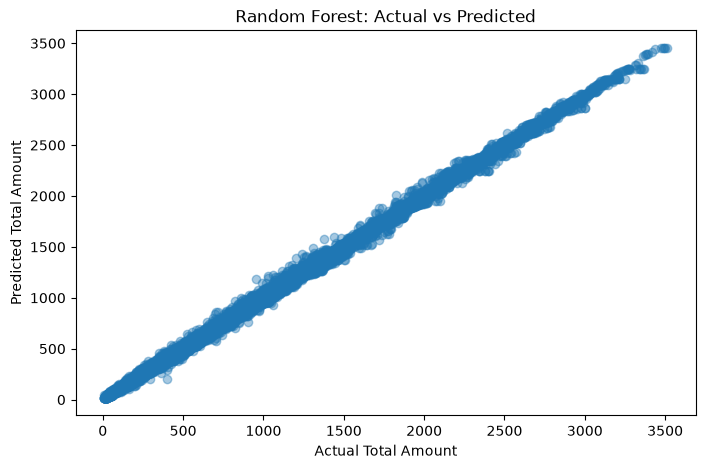

In [326]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(y_reg_test, rf_reg_pred, alpha=0.4)

plt.xlabel("Actual Total Amount")
plt.ylabel("Predicted Total Amount")
plt.title("Random Forest: Actual vs Predicted")

plt.show()

               Model         MAE        RMSE       R2
0  Linear Regression  144.080000  194.280000  0.92750
1      Decision Tree   31.180000   45.000000  0.99610
2      Random Forest   17.501171   25.820313  0.99872


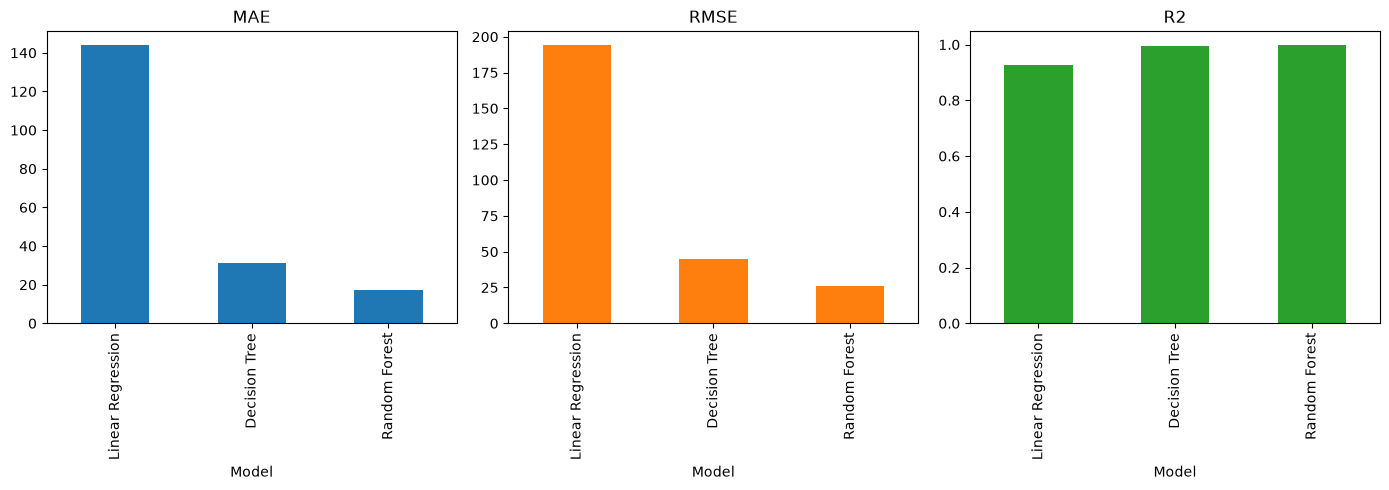

In [327]:
import pandas as pd
import matplotlib.pyplot as plt

reg_results = pd.DataFrame({
    "Model": ["Linear Regression", "Decision Tree", "Random Forest"],
    "MAE": [144.08, 31.18, rf_mae],
    "RMSE": [194.28, 45.00, rf_rmse],
    "R2": [0.9275, 0.9961, rf_r2]
})

print(reg_results)

reg_results.set_index("Model").plot(
    kind="bar",
    subplots=True,
    layout=(1, 3),
    figsize=(14, 5),
    legend=False
)

plt.tight_layout()
plt.show()

In [328]:
# Get feature names after preprocessing
feature_names = rf_reg_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get feature importance
importance = rf_reg_model.named_steps[
    "regressor"
].feature_importances_

# Create table
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

# Sort by importance
importance_df = importance_df.sort_values(
    by="Importance", ascending=False
)

print(importance_df.head(15))

                          Feature    Importance
3                        num__Tax  5.443084e-01
1                  num__UnitPrice  1.853984e-01
0                   num__Quantity  1.665342e-01
14             num__ShippingShare  7.765841e-02
2                   num__Discount  1.492191e-02
13                   num__TaxRate  5.892854e-03
4               num__ShippingCost  5.019049e-03
8                num__HasDiscount  2.641824e-04
11          num__SellerOrderCount  3.276479e-07
6                      num__Month  3.049499e-07
12         num__ProductOrderCount  2.992734e-07
10        num__CustomerOrderCount  2.202765e-07
5                       num__Year  2.046500e-07
34  cat__PaymentMethod_Debit Card  7.854253e-08
61                  cat__State_FL  6.369339e-08


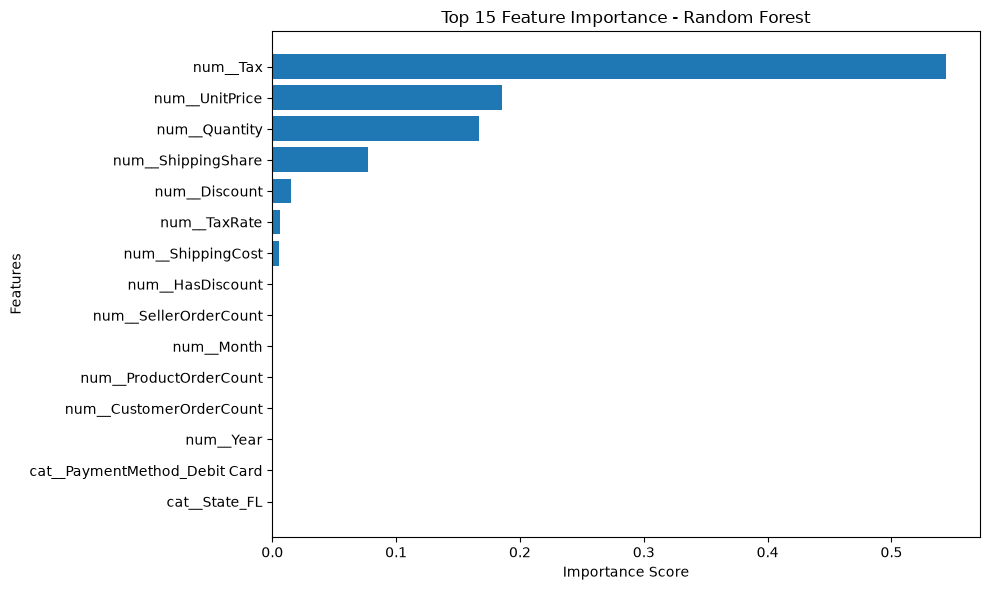

In [329]:
top_features = importance_df.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Top 15 Feature Importance - Random Forest")

plt.tight_layout()
plt.show()

In [330]:
# Total orders
total_orders = len(df)

# Total sales value
total_sales = df["TotalAmount"].sum()

# Order status counts
status_counts = df["OrderStatus"].value_counts()

# Failed orders
failed_orders = status_counts["Returned"] + status_counts["Cancelled"]

# Failure percentage
failure_rate = (failed_orders / total_orders) * 100

# Open orders
open_orders = status_counts["Pending"] + status_counts["Shipped"]

open_rate = (open_orders / total_orders) * 100

print("Total Orders:", total_orders)
print("Total Sales:", round(total_sales, 2))
print("Failed Orders:", failed_orders)
print("Failure Rate:", round(failure_rate, 2), "%")
print("Open Orders:", open_orders)
print("Open Order Rate:", round(open_rate, 2), "%")

Total Orders: 100000
Total Sales: 91825647.92
Failed Orders: 6077
Failure Rate: 6.08 %
Open Orders: 19295
Open Order Rate: 19.3 %


In [331]:
category_sales = df.groupby("Category")["TotalAmount"].sum()

category_sales = category_sales.sort_values(ascending=False)

print(category_sales)

Category
Electronics          15584217.18
Sports & Outdoors    15345571.88
Books                15261837.01
Clothing             15253397.50
Toys & Games         15216684.99
Home & Kitchen       15163939.36
Name: TotalAmount, dtype: float64


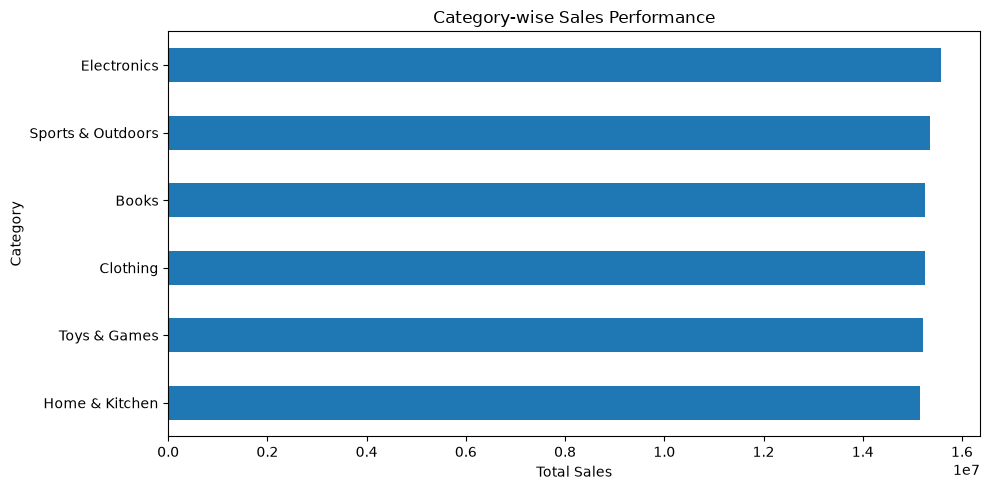

In [332]:
plt.figure(figsize=(10, 5))

category_sales.sort_values().plot(kind="barh")

plt.xlabel("Total Sales")
plt.ylabel("Category")
plt.title("Category-wise Sales Performance")

plt.tight_layout()
plt.show()

Year
2020    18529864.02
2021    18248574.81
2022    18367248.41
2023    18513912.19
2024    18166048.49
Name: TotalAmount, dtype: float64


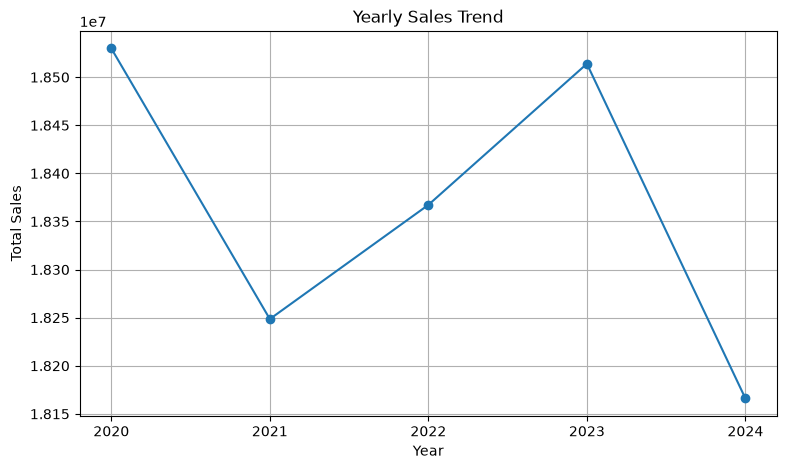

In [333]:
yearly_sales = df.groupby("Year")["TotalAmount"].sum()

print(yearly_sales)

plt.figure(figsize=(9, 5))

plt.plot(
    yearly_sales.index,
    yearly_sales.values,
    marker="o"
)

plt.xlabel("Year")
plt.ylabel("Total Sales")
plt.title("Yearly Sales Trend")
plt.xticks(yearly_sales.index)
plt.grid(True)

plt.show()